# Sesi 01: regresi linear dan prediksi

**Durasi:** 75 menit

Regresi linear adalah alat utama di ekonometrika. Konsepnya sederhana: cari
satu garis yang paling dekat dengan semua titik data, dengan "dekat" diukur
sebagai jumlah kuadrat selisih vertikal (residual).

$$Y_i = \beta_0 + \beta_1 X_{1i} + \beta_2 X_{2i} + \epsilon_i$$

Materi sesi ini:
1. Regresi sederhana dengan scikit-learn dan pelengkap uji statistik.
2. Regresi berganda dan arti koefisien secara ekonomi.
3. Uji t, uji F, R kuadrat, dan R kuadrat terkoreksi (adjusted R2).
4. Prediksi dengan model.

Setiap bagian punya catatan "cara menjelaskan ke mahasiswa" supaya sesi ini
bisa langsung dipakai mengajar.



<!-- alur_belajar -->

**Kaitan dengan materi lain**

| Bekal sebelumnya | Fokus notebook ini | Hasil yang dibawa berikutnya |
|---|---|---|
| Sesi 00: membaca tabel dan pola pada grafik. | Susun X dan y, latih regresi linear, baca koefisien, dan bandingkan aktual dengan prediksi. | Pola residual dan hubungan melengkung mengantar pemilihan bentuk pada Sesi 02. |

**Posisi dalam alur workshop.** Sesi 00 sudah mengenalkan pembacaan data,
EDA, dan grafik. Sesi 01 mulai membentuk model pertama untuk menghubungkan
fitur dengan target. Pola yang tidak cocok dengan garis lurus akan dilanjutkan
pada Sesi 02.

## Persiapan: alamat data

Jalankan sel alamat data di bawah. `URL_DATA` menyimpan alamat folder CSV di GitHub;
`pd.read_csv(...)` membaca tabel sesuai nama CSV pada sel kode berikutnya.
Gunakan koneksi internet dan jalankan sel berurutan dengan **Shift + Enter**.



**Alur sesi:** kita menghubungkan fitur dengan target melalui regresi. Mulai dari tabel **Kenali data**, amati grafik, jalankan model, lalu jelaskan hasilnya dengan kata sendiri. Fokus visual sesi ini adalah perbedaan titik aktual, hasil model, dan residual.

In [1]:
URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

print("Alamat data siap. Jalankan sel pembacaan CSV berikutnya.")

Alamat data siap. Jalankan sel pembacaan CSV berikutnya.


## 1. Data dan pertanyaan penelitian

Kasus dari `data/harga_saham_perusahaan.csv`: apa yang menjelaskan harga saham 50
perusahaan? Variabel: pendapatan per saham (EPS), rasio utang terhadap
ekuitas (DER), dan belanja iklan.

Kita mulai dari satu variabel dulu: EPS. Pertanyaan sederhananya,
"perusahaan dengan EPS lebih tinggi, apakah harga sahamnya juga lebih
tinggi?"



<!-- kamus_variabel:harga_saham_perusahaan.csv -->

### Kenali data: Harga saham perusahaan

**Data:** `data/harga_saham_perusahaan.csv`. **Satu baris:** satu perusahaan pada contoh latihan.

Nama singkat di kode berasal dari penggantian nama kolom CSV; isi angkanya tetap sama.

| Kolom CSV | Nama di kode | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|---|
| `Y_Harga_Saham` | `harga` | Harga satu lembar saham perusahaan. | Uang per lembar; skala mata uang tidak dirinci | Y: target |
| `X1_Pendapatan_per_Saham` | `eps` | EPS (Earnings Per Share): laba per lembar saham; bukan total omzet perusahaan. | Uang per lembar; skala mata uang tidak dirinci | X: penjelas |
| `X2_Rasio_Utang_Ekuitas` | `der` | DER (Debt to Equity Ratio): total utang dibagi ekuitas perusahaan. | Rasio; 1,5 berarti utang 1,5 kali ekuitas (150%) | X: penjelas |
| `X3_Belanja_Iklan` | `iklan` | Jumlah pengeluaran perusahaan untuk iklan. | Uang; skala dan periode belanja tidak dirinci | X: penjelas |

Nama harga, eps, der, dan iklan adalah nama singkat dari kolom di atas. Contoh DER tidak dibaca sebagai 1,5 persen.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


<!-- panduan_perintah -->

**Perintah pada tahap ini.** Baca kegunaan dan masukan sebelum menjalankan contoh. Fungsi yang sudah dijelaskan tidak diulang pada setiap sel.

| Perintah | Untuk apa? | Arti masukan atau argumen | Hasil dan cara membacanya |
|---|---|---|---|
| `pd.read_csv` | Membaca CSV atau TSV menjadi tabel. | Alamat berkas; sep="\t" memilih pemisah tab pada TSV. | DataFrame; periksa nama kolom dan ukuran sebelum analisis. |
| `head` | Melihat contoh isi tabel. | Tanpa angka menampilkan lima baris; head(10) menampilkan sepuluh. | Cuplikan awal, bukan ringkasan seluruh data. |
| `rename` | Memperjelas nama kolom tanpa mengganti angka. | columns berisi pasangan nama lama dan nama baru. | Tabel dengan nama kolom baru; simpan kembali bila ingin dipakai sel berikutnya. |
| `set_theme, rcParams, dan label grafik` | Membuat grafik terbaca konsisten. | Tema, ukuran huruf, DPI, judul, xlabel/ylabel, legend, dan tight_layout. | Mengubah tampilan, bukan nilai model; plt.show() menampilkan grafik di notebook. |

In [2]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette=["#2F5D50", "#C15937", "#D9A441", "#5B8A8F"])
plt.rcParams.update({"figure.dpi": 150, "axes.titleweight": "bold", "font.size": 11})

saham = pd.read_csv(URL_DATA + "harga_saham_perusahaan.csv")
saham = saham.rename(
    columns={
        "Y_Harga_Saham": "harga",
        "X1_Pendapatan_per_Saham": "eps",
        "X2_Rasio_Utang_Ekuitas": "der",
        "X3_Belanja_Iklan": "iklan",
    }
)
saham.head()

plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "legend.fontsize": 10})

## 2. Lihat data dulu, selalu

Satu scatter plot sebelum regresi. Polanya hampir linear sempurna, sinyal
bahwa regresi linear masuk akal untuk hubungan ini.



<!-- panduan_perintah -->

**Perintah pada tahap ini.** Baca kegunaan dan masukan sebelum menjalankan contoh. Fungsi yang sudah dijelaskan tidak diulang pada setiap sel.

| Perintah | Untuk apa? | Arti masukan atau argumen | Hasil dan cara membacanya |
|---|---|---|---|
| `subplots, scatter, dan plot` | Membuat ruang grafik lalu menampilkan hubungan atau pola waktu. | figsize ukuran; scatter untuk titik, plot untuk garis; sumbu dan satuan diberi label. | Titik menunjukkan pengamatan; garis mengikuti urutan X sehingga data perlu diurutkan bila perlu. |

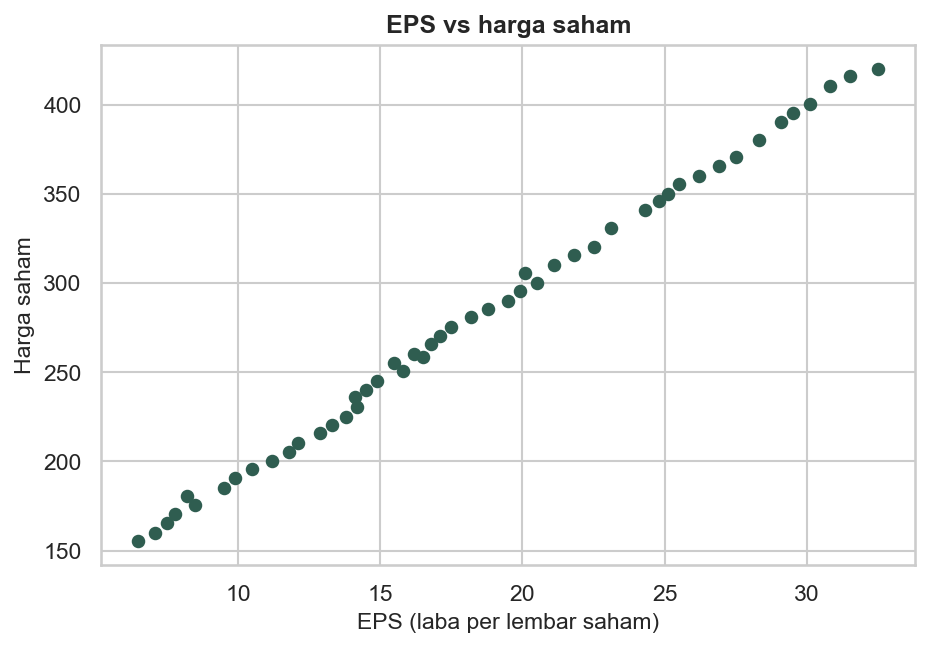

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(saham["eps"], saham["harga"], color="#2F5D50", s=30)
ax.set_xlabel("EPS (laba per lembar saham)")
ax.set_ylabel("Harga saham")
ax.set_title("EPS vs harga saham")
plt.show()

**Baca grafik sebelum lanjut:** Satu titik mewakili satu pengamatan. Baca nama dan satuan kedua sumbu, lalu jelaskan arah hubungan serta sebaran titik. Pola visual dipakai untuk memahami model berikutnya, bukan sebagai bukti kausal.

## 3. Regresi sederhana

Siapkan tabel X dan kolom y. `LinearRegression()` menyertakan intersep
secara otomatis; `fit(X, y)` menghitung koefisien dengan metode OLS.



<!-- panduan_perintah -->

**Perintah pada tahap ini.** Baca kegunaan dan masukan sebelum menjalankan contoh. Fungsi yang sudah dijelaskan tidak diulang pada setiap sel.

| Perintah | Untuk apa? | Arti masukan atau argumen | Hasil dan cara membacanya |
|---|---|---|---|
| `dropna` | Membentuk sampel dengan kolom yang dibutuhkan terisi. | Pilih kolom model dahulu, lalu dropna(); subset membatasi kolom pemeriksaan. | Tabel baru; baris terbuang dapat mengubah komposisi sampel. |
| `pd.Series` | Menyusun satu kolom bernama atau koefisien berlabel. | Nilai dan index sebagai label; name memberi nama kolom. | Series; label membantu mencocokkan koefisien, prediksi, dan baris asal. |
| `loc dan iloc` | Memilih baris atau kolom secara jelas. | loc memakai label atau kondisi; iloc memakai posisi mulai 0; dua titik berarti seluruh rentang. | Bagian tabel; pertahankan indeks agar y dan prediksi sejajar. |
| `LinearRegression` | Menyiapkan regresi linear dengan scikit-learn. | fit_intercept=True adalah bawaan; X tabel dua dimensi, y satu target. | Estimator yang belum dilatih; koefisien baru tersedia setelah fit. |
| `fit` | Mengestimasi parameter model. | scikit-learn: fit(X_train, y_train); paket statistik: fit() sesudah model menerima data. | Parameter dipelajari dari sampel yang diberikan; data uji tidak dipakai untuk melatih. |
| `coef_ dan intercept_` | Membaca kemiringan dan intersep model scikit-learn. | Atribut tanpa tanda kurung; urutan coef_ mengikuti kolom X. | Linear: perubahan prediksi y per satu unit X, dengan fitur lain tetap; logit memakai skala log-odds. |
| `score` | Meringkas kecocokan model pada data yang diberikan. | X dan y evaluasi; LinearRegression mengembalikan R². | R² dapat negatif pada data uji; score klasifikasi umumnya akurasi, jadi baca jenis modelnya. |
| `sm.add_constant` | Menambahkan kolom intersep untuk pelengkap statistik. | X yang sama; has_constant="add" meminta kolom konstan. | Matriks X uji; scikit-learn sudah menghitung intersep sendiri sehingga tidak perlu kolom ini. |
| `sm.OLS` | Menghitung standard error dan pengujian regresi linear. | Urutan OLS(y, X_uji), lalu fit(); X_uji mencakup intersep. | Hasil inferensi pada sampel yang sama; model prediksi utama tetap scikit-learn. |
| `summary, pvalues, dan bse` | Membaca ringkasan hasil statistik. | Objek hasil fit; bse adalah standard error dan pvalues adalah p-value. | Nilai p menguji hipotesis sesuai asumsi, bukan ukuran besarnya dampak atau bukti kausalitas. |

In [4]:
sampel_model1 = saham[["harga", "eps"]].dropna()
X_model1 = sampel_model1[["eps"]]
y_model1 = sampel_model1["harga"]

model1 = LinearRegression()
model1.fit(X_model1, y_model1)

koefisien_model1 = pd.Series(model1.coef_, index=X_model1.columns)
koefisien_model1.loc["Intercept"] = model1.intercept_

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [5]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
X_uji_model1 = sm.add_constant(X_model1, has_constant="add")
X_uji_model1 = X_uji_model1.rename(columns={"const": "Intercept"})
uji_model1 = sm.OLS(y_model1, X_uji_model1).fit()
print(uji_model1.summary())

                            OLS Regression Results                            
Dep. Variable:                  harga   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 2.487e+04
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           7.85e-67
Time:                        23:39:53   Log-Likelihood:                -131.31
No. Observations:                  50   AIC:                             266.6
Df Residuals:                      48   BIC:                             270.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     87.8469      1.309     67.125      0.0

### Cara membaca tabel output

Tiga angka yang paling sering dipakai:

- `coef` pada baris `Intercept`: nilai Y saat X = 0. Di kasus ini artinya
  harga saham teoretis saat EPS nol. Tidak selalu masuk akal secara bisnis,
  tapi tetap harus dilaporkan.
- `coef` pada baris `eps`: perubahan Y untuk tambahan satu unit X.
  Inilah jawaban dari pertanyaan penelitian.
- `P>|t|`: p-value uji t. Jika koefisien populasi nol dan asumsi uji
  berlaku, ini peluang memperoleh statistik uji setidaknya seekstrem
  yang diamati. Di bawah 0,05 berarti signifikan pada taraf 5%.

Kolom `R-squared` mengukur proporsi variasi Y yang diterangkan model.
Hati-hati: data simulasi seperti `harga_saham_perusahaan.csv` punya R kuadrat sangat tinggi
karena dibangkitkan dari formula yang rapi. Di data riil, R kuadrat 0,3
sampai 0,6 untuk data cross-section sudah wajar.



In [6]:
b0 = koefisien_model1["Intercept"]
b1 = koefisien_model1["eps"]
print(f"Intersep  : {b0:.3f}")
print(f"Slope     : {b1:.3f}")
print(f"R-squared : {model1.score(X_model1, y_model1):.3f}")
print(f"p-value eps: {uji_model1.pvalues['eps']:.3g}")

Intersep  : 87.847
Slope     : 10.410
R-squared : 0.998
p-value eps: 7.85e-67


### Visual: perbesar satu residual

Panel kiri menunjukkan seluruh data dan garis prediksi. Panel kanan
memperbesar pengamatan pertama, dipilih dengan `iloc[0]`, supaya jarak
antara harga aktual dan prediksi terlihat. Posisi pertama di Python bernomor 0.

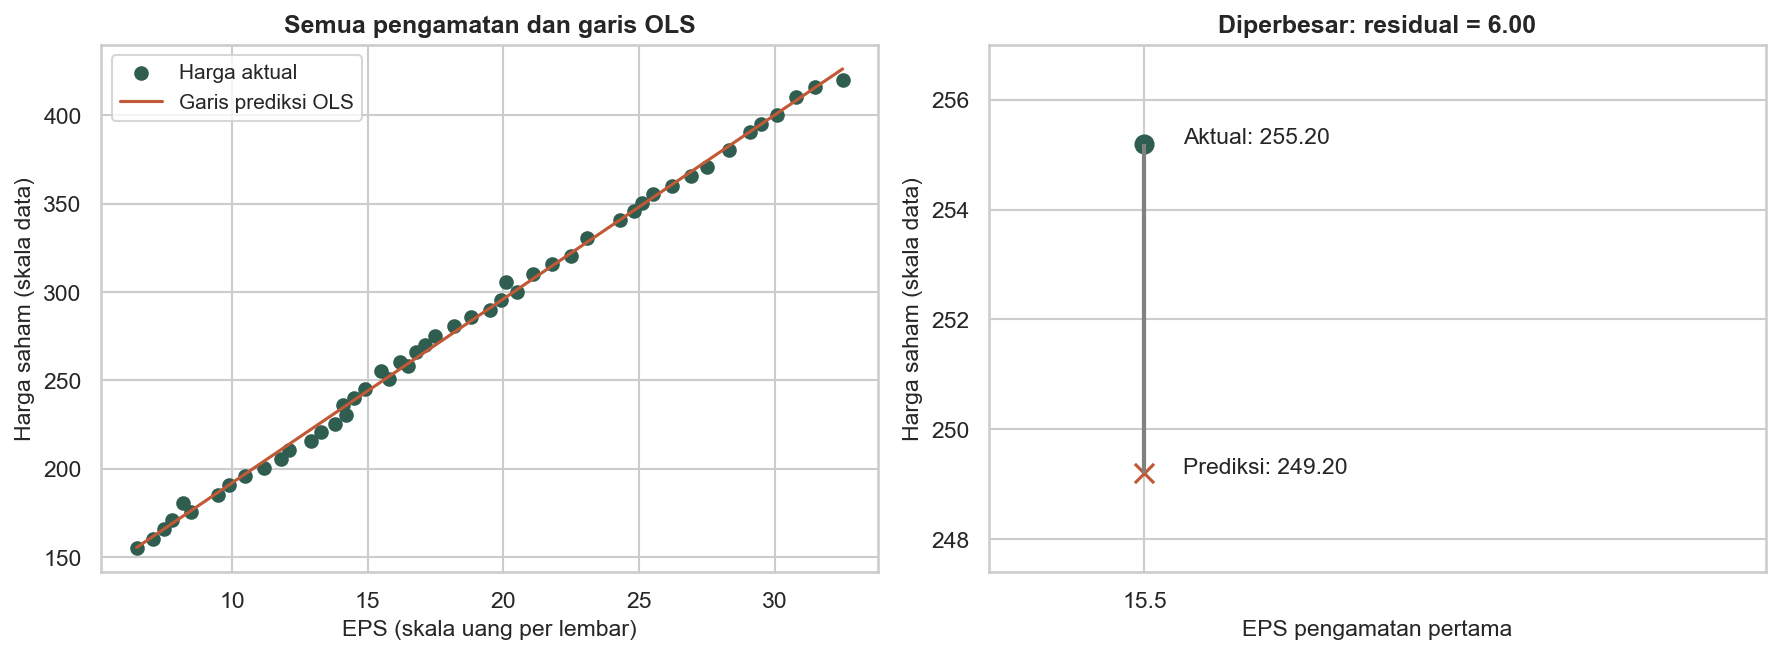

In [7]:
contoh = saham.iloc[0]
harga_prediksi = b0 + b1 * contoh["eps"]
residual_contoh = contoh["harga"] - harga_prediksi

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(saham["eps"], saham["harga"], color="#2F5D50", label="Harga aktual")
xs = np.linspace(saham["eps"].min(), saham["eps"].max(), 50)
axes[0].plot(xs, b0 + b1 * xs, color="#C15937", label="Garis prediksi OLS")
axes[0].set(xlabel="EPS (skala uang per lembar)", ylabel="Harga saham (skala data)", title="Semua pengamatan dan garis OLS")
axes[0].legend()
axes[1].scatter(contoh["eps"], contoh["harga"], color="#2F5D50", s=75)
axes[1].scatter(contoh["eps"], harga_prediksi, color="#C15937", marker="x", s=85)
axes[1].vlines(contoh["eps"], contoh["harga"], harga_prediksi, color="gray", linewidth=2)
axes[1].text(contoh["eps"] + 0.05, contoh["harga"], f"Aktual: {contoh['harga']:.2f}")
axes[1].text(contoh["eps"] + 0.05, harga_prediksi, f"Prediksi: {harga_prediksi:.2f}")
axes[1].set_xlim(contoh["eps"] - 0.2, contoh["eps"] + 0.8)
axes[1].set_xticks([contoh["eps"]])
axes[1].margins(y=0.3)
axes[1].set(xlabel="EPS pengamatan pertama", ylabel="Harga saham (skala data)", title=f"Diperbesar: residual = {residual_contoh:.2f}")
plt.tight_layout()
plt.show()

**Cara membaca:** di kanan, titik hijau adalah harga aktual dan tanda
silang oranye adalah prediksi pada EPS yang sama. Garis abu-abu menghubungkan
keduanya. Residual dihitung sebagai aktual dikurangi prediksi: negatif jika
aktual di bawah prediksi, positif jika di atas. Panel kanan memakai rentang
sumbu yang diperbesar sehingga jaraknya terlihat jelas.

### Coba sendiri (5 menit)

Ganti variabel penjelas dari `eps` ke `der` dan jalankan regresinya.
Apakah `der` signifikan? Lalu, kenapa hasilnya berbeda dengan model
berganda di bagian 6 nanti?

Tulis di sel di bawah, baru buka jawabannya.



In [8]:
# Tulis kode Anda di sini

<details><summary>Lihat jawaban</summary>

Sendirian, `der` tampak sangat signifikan (koefisien -131,3; p = 0,0000;
R2 = 0,93). Tapi di model berganda (bagian 6) `der` justru tidak
signifikan. Pelajaran: koefisien sederhana bisa menyesatkan karena
mencampur pengaruh variabel lain, dalam hal ini EPS.

</details>



## 4. Arti koefisien dengan angka

Dari output di atas, slope sekitar 10,4. Artinya: kenaikan EPS satu unit
diiringi kenaikan harga saham sekitar 10,4 unit, dengan asumsi hal lain
tidak berubah. Intersep sekitar 87,8 adalah titik potong teoretis di EPS = 0.



## 5. Prediksi

Prediksi adalah alasan orang membangun model. Di statsmodels, pakai
`predict` dengan DataFrame berisi nilai X baru. Perhatikan bentuk datanya:
harus DataFrame, bukan angka tunggal.



<!-- panduan_perintah -->

**Perintah pada tahap ini.** Baca kegunaan dan masukan sebelum menjalankan contoh. Fungsi yang sudah dijelaskan tidak diulang pada setiap sel.

| Perintah | Untuk apa? | Arti masukan atau argumen | Hasil dan cara membacanya |
|---|---|---|---|
| `pd.DataFrame` | Menyusun beberapa kolom menjadi tabel. | Dictionary: nama kolom di kiri, daftar nilai di kanan; panjang daftar harus sama. | DataFrame; satu baris mempunyai arti sesuai unit pengamatan kasus. |
| `predict` | Menghitung prediksi dari model yang sudah dilatih. | Tabel X baru dengan nama dan urutan fitur seperti saat fit. | Satu prediksi tiap baris; ketepatan pada data uji tetap harus diukur. |

In [9]:
baru = pd.DataFrame({"eps": [15.0, 20.0, 25.0]})
baru["prediksi_harga"] = pd.Series(model1.predict(baru[["eps"]]), index=baru.index)
baru

,eps,prediksi_harga
0,15.0,243.998891
1,20.0,296.049546
2,25.0,348.100201


Prediksi manual untuk satu nilai juga mudah: `b0 + b1 * eps`. Hasilnya
harus sama persis dengan `model1.predict(pd.DataFrame({"eps": [15]}))`,
selisih hanya mungkin dari pembulatan.



## 6. Regresi berganda

Sekarang kasusnya dilengkapi: harga saham dijelaskan EPS, DER, dan belanja
iklan sekaligus.



<!-- panduan_perintah -->

**Perintah pada tahap ini.** Baca kegunaan dan masukan sebelum menjalankan contoh. Fungsi yang sudah dijelaskan tidak diulang pada setiap sel.

| Perintah | Untuk apa? | Arti masukan atau argumen | Hasil dan cara membacanya |
|---|---|---|---|
| `axhline dan axvline` | Memberi patokan pada grafik. | y untuk garis horizontal, x untuk garis vertikal; linestyle mengatur pola garis. | Contoh: residual nol, periode program, atau batas latihan/uji; bukan hasil estimasi tambahan. |

In [10]:
sampel_model2 = saham[["harga", "eps", "der", "iklan"]].dropna()
X_model2 = sampel_model2[["eps", "der", "iklan"]]
y_model2 = sampel_model2["harga"]

model2 = LinearRegression()
model2.fit(X_model2, y_model2)

koefisien_model2 = pd.Series(model2.coef_, index=X_model2.columns)
koefisien_model2.loc["Intercept"] = model2.intercept_

### Lihat hasil model: Harga saham (skala data)

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

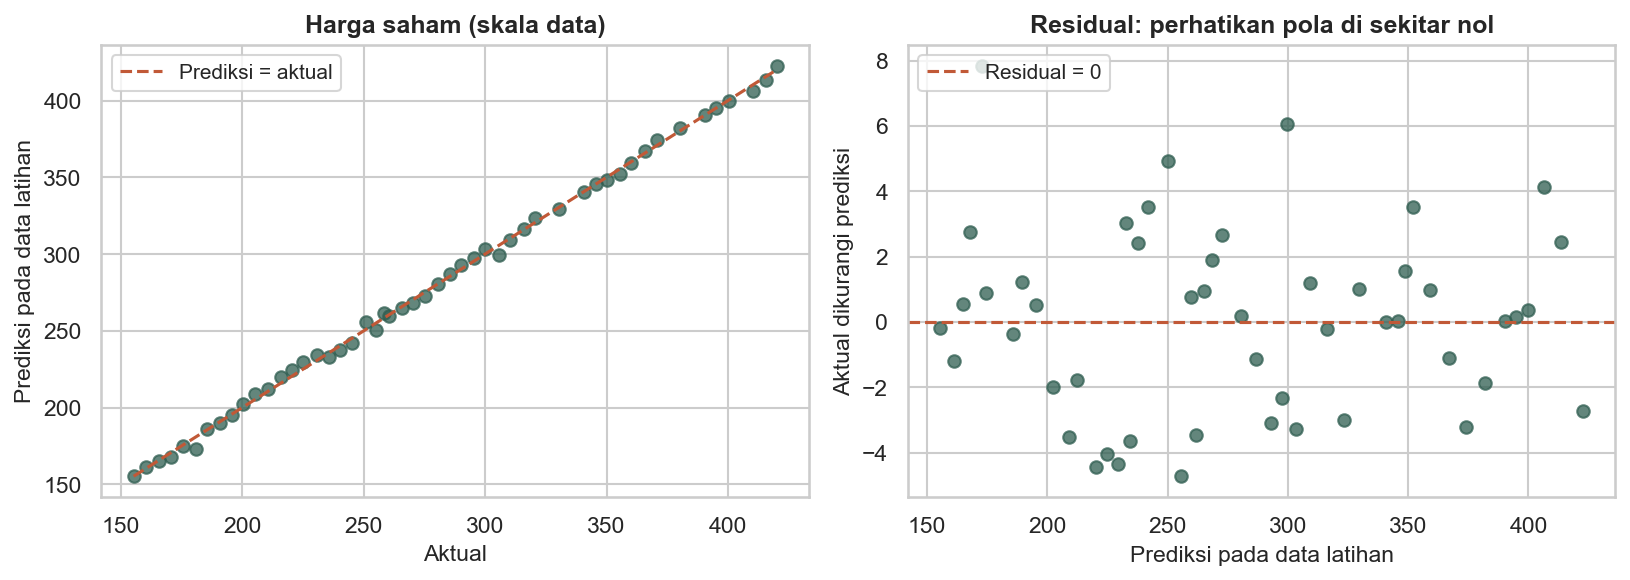

In [11]:
prediksi_visual = model2.predict(X_model2)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model2, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model2.min(), y_model2.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937", label="Prediksi = aktual")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Harga saham (skala data)")
axes[1].scatter(prediksi_visual, y_model2 - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--", label="Residual = 0")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
axes[0].legend(loc="upper left")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [12]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
X_uji_model2 = sm.add_constant(X_model2, has_constant="add")
X_uji_model2 = X_uji_model2.rename(columns={"const": "Intercept"})
uji_model2 = sm.OLS(y_model2, X_uji_model2).fit()
print(uji_model2.summary())

                            OLS Regression Results                            
Dep. Variable:                  harga   R-squared:                       0.999
Model:                            OLS   Adj. R-squared:                  0.999
Method:                 Least Squares   F-statistic:                 1.121e+04
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           7.14e-66
Time:                        23:39:54   Log-Likelihood:                -122.71
No. Observations:                  50   AIC:                             253.4
Df Residuals:                      46   BIC:                             261.1
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     74.1642     12.242      6.058      0.0

### Uji F: apakah model berguna secara keseluruhan?

`Prob (F-statistic)` menguji hipotesis bahwa semua slope sama dengan nol.
Kalau p-value kecil, setidaknya ada satu variabel yang menjelaskan Y.



In [13]:
print(f"F-statistic : {uji_model2.fvalue:.3f}")
print(f"Prob (F)    : {uji_model2.f_pvalue:.6g}")
print(f"R2          : {model2.score(X_model2, y_model2):.4f}")
print(f"Adj R2      : {uji_model2.rsquared_adj:.4f}")

F-statistic : 11211.581
Prob (F)    : 7.13948e-66
R2          : 0.9986
Adj R2      : 0.9985


### Koefisien satu per satu

Uji t di tabel output adalah uji parsial: apakah satu koefisien signifikan
setelah variabel lain diperhitungkan. Ini berbeda dari korelasi biasa,
karena pengaruh variabel lain sudah "dibersihkan".



In [14]:
tabel = pd.DataFrame(
    {
        "koefisien": koefisien_model2,
        "std_err": uji_model2.bse,
        "t": uji_model2.tvalues,
        "p_value": uji_model2.pvalues,
    }
)
tabel

,koefisien,std_err,t,p_value
Intercept,74.164208,12.242411,6.057974,2.370469e-07
der,2.941357,4.162148,0.706692,4.833224e-01
eps,8.097857,0.577223,14.028981,3.118340e-18
iklan,0.854130,0.263025,3.247340,2.177558e-03


Di data ini, EPS dan iklan signifikan, sementara DER tidak. Kenaikan DER
satu unit berhubungan dengan kenaikan harga 2,94 unit, tapi p-value 0,48
artinya angka itu belum bisa dibedakan dari nol secara statistik.



### Coba sendiri (5 menit)

Pakai `model2` (harga ~ eps + der + iklan). Prediksi harga untuk
EPS = 18, DER = 1,5, dan belanja iklan = 60.

Tulis di sel di bawah, baru buka jawabannya.



In [15]:
# Tulis kode Anda di sini

<details><summary>Lihat jawaban</summary>

`model2.predict(pd.DataFrame({"eps": [18], "der": [1.5], "iklan": [60]}))`
menghasilkan sekitar 275,6.

</details>



## 7. Kapan garis lurus tidak cukup

Coba regresikan penjualan pada biaya iklan memakai `iklan_penjualan.csv`.
Hubungannya melengkung, dan model linear gagal total: R kuadrat hanya
sekitar 0,007 dan slope tidak signifikan. Ini bukan alasan untuk menyerah,
tapi tanda bahwa bentuk fungsionalnya perlu diganti. Itu topik Sesi 02.



<!-- kamus_variabel:iklan_penjualan.csv -->

### Kenali data: Iklan dan penjualan

**Data:** `data/iklan_penjualan.csv`. **Satu baris:** satu tahun pengamatan pada contoh latihan.

Nama singkat di kode berasal dari penggantian nama kolom CSV; isi angkanya tetap sama.

| Kolom CSV | Nama di kode | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|---|
| `Tahun ke-` | `Tahun ke-` | Urutan tahun pengamatan, bukan tahun kalender. | 1, 2, 3, dan seterusnya | Penanda waktu |
| `Biaya Iklan (X)` | `iklan` | Biaya yang dikeluarkan untuk memasang iklan. | Satuan/skala tidak dirinci sumber | X: penjelas |
| `Penjualan (Y)` | `penjualan` | Besarnya penjualan yang ingin dijelaskan oleh biaya iklan. | Satuan/skala tidak dirinci sumber | Y: target |

Jangan menetapkan rupiah, juta rupiah, atau unit barang hanya dari besar angkanya; skala tersebut tidak dicantumkan pada sumber tabel.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [16]:
iklan = pd.read_csv(URL_DATA + "iklan_penjualan.csv")
iklan = iklan.rename(columns={"Biaya Iklan (X)": "iklan", "Penjualan (Y)": "penjualan"})

iklan.head()

,Tahun ke-,iklan,penjualan
0,1,5.0,30.1
1,2,6.5,36.2
2,3,8.0,42.5
3,4,9.5,48.8
4,5,11.0,54.1


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [17]:
sampel_model_salah = iklan[["penjualan", "iklan"]].dropna()
X_model_salah = sampel_model_salah[["iklan"]]
y_model_salah = sampel_model_salah["penjualan"]

In [18]:
model_salah = LinearRegression()
model_salah.fit(X_model_salah, y_model_salah)

prediksi_model_salah = pd.Series(
    model_salah.predict(X_model_salah), index=y_model_salah.index
)

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

R2 linear  : 0.0066
p-value iklan: 0.670


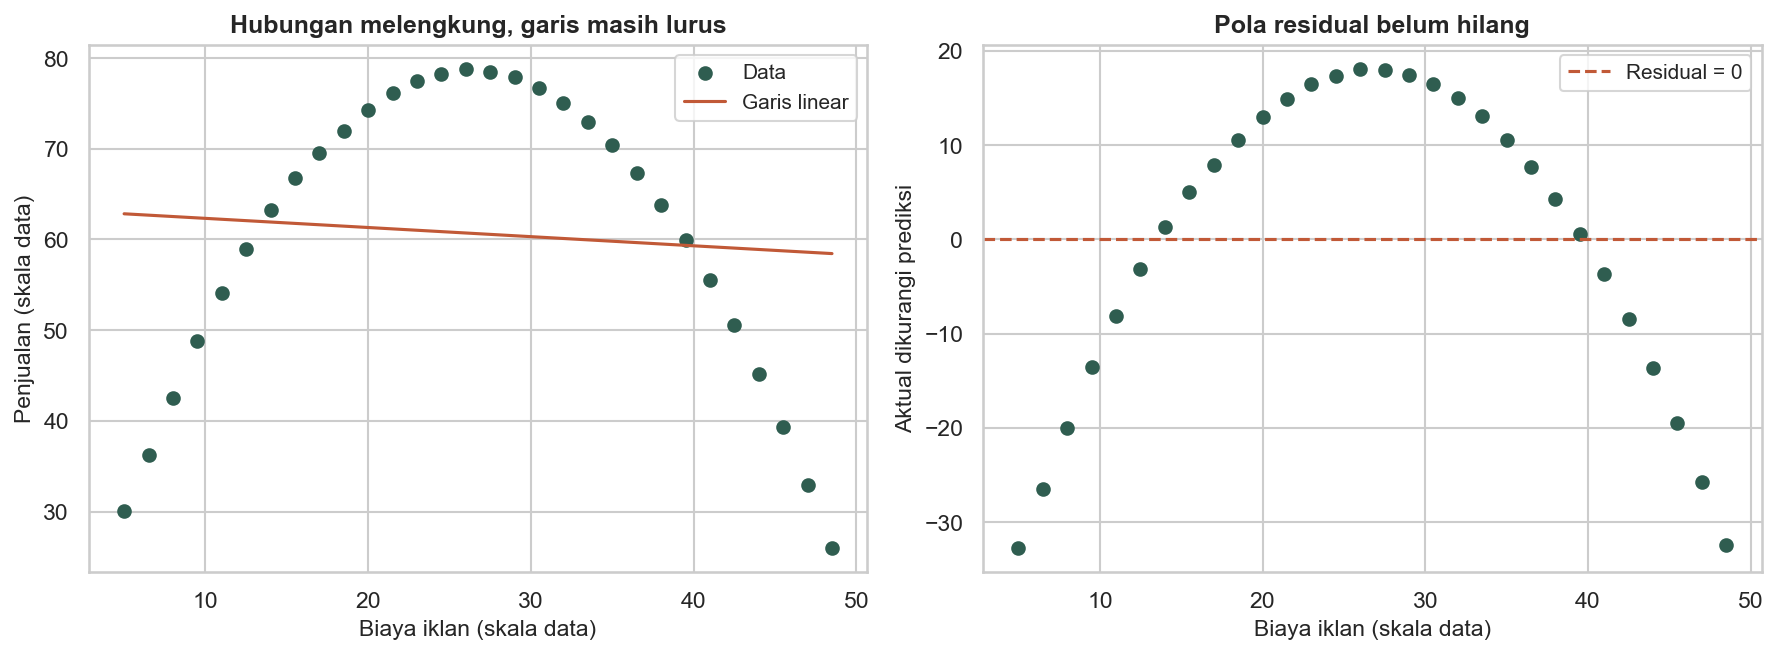

In [19]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
X_uji_model_salah = sm.add_constant(X_model_salah, has_constant="add")
X_uji_model_salah = X_uji_model_salah.rename(columns={"const": "Intercept"})
uji_model_salah = sm.OLS(y_model_salah, X_uji_model_salah).fit()
print(f"R2 linear  : {model_salah.score(X_model_salah, y_model_salah):.4f}")
print(f"p-value iklan: {uji_model_salah.pvalues['iklan']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(iklan["iklan"], iklan["penjualan"], color="#2F5D50", label="Data")
axes[0].plot(iklan["iklan"], prediksi_model_salah, color="#C15937", label="Garis linear")
axes[0].set(xlabel="Biaya iklan (skala data)", ylabel="Penjualan (skala data)", title="Hubungan melengkung, garis masih lurus")
axes[0].legend()
axes[1].scatter(iklan["iklan"], iklan["penjualan"] - prediksi_model_salah, color="#2F5D50")
axes[1].axhline(0, color="#C15937", linestyle="--", label="Residual = 0")
axes[1].set(xlabel="Biaya iklan (skala data)", ylabel="Aktual dikurangi prediksi", title="Pola residual belum hilang")
axes[1].legend()
plt.tight_layout()
plt.show()

**Cara membaca:** di kiri, garis lurus melewatkan pola naik lalu turun
pada penjualan. Di kanan, residual masih membentuk lengkungan yang teratur.
Pola ini memberi alasan untuk memeriksa bentuk kuadratik pada Sesi 02.
Rendahnya kecocokan di sini berasal dari contoh bentuk linear yang tidak sesuai.

## 8. Catatan mengajar: tiga kesalahan yang paling sering muncul

**Satu, menafsirkan intersep tanpa berpikir.** "Harga saham 87,8 padahal
EPS nol" sering diucapkan seolah itu temuan. Intersep hanya berguna kalau
X = 0 masuk akal secara ekonomi.

**Dua, menyamakan R kuadrat tinggi dengan model benar.** Model dengan R
kuadrat 0,95 bisa saja salah spesifikasi, misalnya karena tren palsu
(spurious regression) pada data deret waktu. Ingat sesi 5.

**Tiga, lupa satuan.** Koefisien 10,4 pada EPS diukur dalam satuan Y per
satuan X. Kalau Y rupiah dan X persen, 10,4 berarti 10,4 rupiah per satu
persen, bukan per 0,01 persen.

Satu lagi yang sering luput: koefisien bersifat *ceteris paribus*, bukan
pengaruh kausal. Bilang "berhubungan dengan" kecuali desain penelitiannya
memang memungkinkan klaim kausal.



## Latihan

1. Regresikan `produktivitas padi` pada pupuk, curah hujan, dan sinar
   matahari (`produktivitas_padi.csv`). Laporkan koefisien, p-value, dan R kuadrat.
2. Prediksi produktivitas kalau pupuk 160, curah hujan 1900, sinar 230.
3. Setelah model Latihan 1 jadi (variabel `model_padi`), uji apakah
   pupuk dan sinar matahari bersama-sama signifikan:
   `model_padi.f_test("X1_Jumlah_Pupuk = 0, X3_Sinar_Matahari = 0")`.

Kunci dan interpretasi ada di `pengajar/README.md#pembahasan-latihan`.



## Selanjutnya

Kerjakan [Lab 01](https://colab.research.google.com/github/akhiyarwaladi/ekonometrika_coding_workshop/blob/main/materi/02_latihan/01_regresi_dasar.ipynb) untuk mengulang materi ini. Lanjutkan ke [Sesi 02: bentuk fungsional model regresi](https://colab.research.google.com/github/akhiyarwaladi/ekonometrika_coding_workshop/blob/main/materi/01_ekonometrika/02_bentuk_fungsional.ipynb).